# E4 · Auditoría de datos frente a las hipótesis — SmartFruit
## Actualización del E4 alineada al MVP integrado · 18/11/2026

**Capstone Project I · Maestría en Ciencia de Datos e IA · UTEC Posgrado**

| Campo | SmartFruit |
|---|---|
| Equipo | SmartFruit |
| Proyecto | Inspección inteligente de limes para apoyar Quality Control |
| Integrantes | Mayra Del Río · Marina Ludeña · Cristian Marquina · Lucia Bazán |
| Asesor | Itamar Salazar |

### Alcance de la actualización

El preregistro H1–H3 y los resultados históricos del E4 se conservan como evidencia metodológica. Las secciones incorporadas al final documentan la evolución posterior del proyecto y su relación con el MVP integrado.

**Fuentes históricas de auditoría**
- **ACC-1 · Reportes QC:** 106 reportes únicos; H1 utiliza una muestra formal de 100.
- **ACC-2 · IMP / Repack Loss:** fuente histórica para el análisis exploratorio de pérdida posterior.
- **ACC-3 a ACC-6:** reportes y fotografías de apoyo, matriz QC y referencias visuales.
- **ACC-7 · Vision:** dataset y artefactos visuales para conteo de frutos y clasificación de oleocelosis.

**Fuentes operativas del MVP**
- **ACC-9 · Reception Manifest:** contexto por lote/paleta y `expected_count_per_box`.
- **ACC-10 · Vision outputs:** resultados JSON por fotografía.
- **ACC-11 · Captura integrada / QC Report:** cajas, agregados Vision, defectos manuales, severidad, recomendación y decisión humana.

La aplicación utiliza pesos y módulos de inferencia ya entrenados. El componente de estimación de pérdida posterior permanece desacoplado de la recomendación operativa.

Las unidades de análisis dependen del componente: lote, paleta/muestra, caja, fotografía, fruto/crop o Work Order histórico.


## 0 · Configuración


In [1]:
# ============ CONFIGURACIÓN DEL EQUIPO ============
MODO_DEMO = False
SEMILLA = 42

MOMENTO_DECISION = (
    "Después de inspeccionar la primera caja/muestra del lote o pallet y antes de cerrar QC, "
    "el equipo decide si mantiene el muestreo estándar o amplía la revisión."
)

# H1 se contrasta con una muestra formal de 100 reportes de 2026.
N_H1 = 100

# Archivos esperados. El notebook los busca automáticamente en cwd, /content y /mnt/data.
NOMBRE_ARCHIVO_QC = "reportesMD.7z"
NOMBRE_IMP = "Weight IN - OUT by lot - item.xlsx"

import warnings, os, re, hashlib, shutil, subprocess, sys
from pathlib import Path
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.figsize": (8, 3.8), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
rng = np.random.default_rng(SEMILLA)

print("Momento de decisión:", MOMENTO_DECISION)
print("Versiones → pandas", pd.__version__, "| numpy", np.__version__)


# ============ DATASET VISUAL (ACC-7 / H3) ============
VISUAL_SHARED_FOLDER_URL = ""
VISUAL_DIR_NAME = "smartfruit_visual"
VISUAL_PILOT_N = 50

# Umbrales del protocolo / H3
MIN_USABLE_RATE = 0.90
MIN_CLASS_SHARE = 0.30
MIN_KAPPA = 0.80

# Estas métricas automáticas son SOLO banderas para revisión humana, no sustituyen a los 2 evaluadores.
MIN_SHORT_SIDE_PX = 1000
MIN_BLUR_SCORE = 80.0
MIN_BRIGHTNESS = 40.0
MAX_BRIGHTNESS = 220.0
MAX_HIGHLIGHT_RATIO = 0.10


Momento de decisión: Después de inspeccionar la primera caja/muestra del lote o pallet y antes de cerrar QC, el equipo decide si mantiene el muestreo estándar o amplía la revisión.
Versiones → pandas 2.2.3 | numpy 2.3.5


### 0.1 · Funciones auxiliares


In [2]:
def buscar_archivo(nombre):
    candidatos = [Path.cwd(), Path('/content'), Path('/mnt/data')]
    for base in candidatos:
        if not base.exists():
            continue
        p = base / nombre
        if p.exists():
            return p
        matches = list(base.rglob(nombre))
        if matches:
            return matches[0]
    return None


def buscar_directorio_reportes():
    """Busca una carpeta con archivos QC, aunque el workbook IMP esté separado."""
    candidatos = [Path.cwd(), Path('/content'), Path('/mnt/data')]
    for base in candidatos:
        if not base.exists():
            continue
        opciones = [base/'reportesMD', base/'extracted_md'/'reportesMD', base/'_smartfruit_data'/'reportesMD']
        for d in opciones:
            if d.exists():
                qc_files = [p for p in d.iterdir() if p.suffix.lower() in {'.xlsx','.csv'} and p.name != NOMBRE_IMP]
                if qc_files:
                    return d
    return None


def preparar_fuentes():
    """Devuelve el directorio con reportes QC. Si solo existe el .7z, lo extrae."""
    d = buscar_directorio_reportes()
    if d is not None:
        print("Usando directorio QC ya extraído:", d)
        return d

    archive = buscar_archivo(NOMBRE_ARCHIVO_QC)
    if archive is None:
        raise FileNotFoundError(
            f"No encontré {NOMBRE_ARCHIVO_QC}. Súbanlo al mismo entorno del notebook."
        )

    out = Path.cwd() / '_smartfruit_data'
    out.mkdir(exist_ok=True)
    try:
        import py7zr
    except ImportError:
        print("Instalando py7zr para extraer el archivo .7z...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'py7zr'])
        import py7zr
    with py7zr.SevenZipFile(archive, mode='r') as z:
        z.extractall(path=out)

    d = out / 'reportesMD'
    if not d.exists():
        d = out
    print("QC extraído en:", d)
    return d
def _txt(x):
    return '' if pd.isna(x) else str(x).strip()


def _find_label_value(raw, label):
    target = label.lower()
    for r in range(raw.shape[0]):
        for c in range(raw.shape[1]):
            s = _txt(raw.iat[r, c])
            if s.lower().startswith(target):
                if ':' in s:
                    after = s.split(':', 1)[1].strip()
                    if after:
                        return after
                for cc in range(c + 1, min(raw.shape[1], c + 5)):
                    v = raw.iat[r, cc]
                    if pd.notna(v) and _txt(v):
                        return v
    return np.nan


def _find_header_row(raw):
    for r in range(raw.shape[0]):
        vals = [_txt(v).lower() for v in raw.iloc[r].tolist()]
        if any('pallet' in v for v in vals) and 'sample' in vals:
            return r
    return None


def _norm_col(s):
    s = _txt(s).replace('\n', ' ').lower()
    s = re.sub(r'[^a-z0-9]+', '_', s).strip('_')
    return s or 'unnamed'


def _norm_lot(v):
    if pd.isna(v):
        return np.nan
    try:
        return str(int(float(v)))
    except Exception:
        return str(v).strip()


def _norm_size(v):
    if pd.isna(v):
        return None
    s = str(v).upper().strip()
    if '10X1' in s or '1LB' in s:
        return 'KEY'
    m = re.search(r'(\d{2,3})', s)
    return m.group(1) if m else re.sub(r'[^A-Z0-9]', '', s)


def parse_qc_report(path):
    path = Path(path)
    if path.suffix.lower() == '.csv':
        raw = pd.read_csv(path, header=None, dtype=object)
    else:
        raw = pd.read_excel(path, sheet_name='Report', header=None, dtype=object)

    inspection_date = pd.to_datetime(_find_label_value(raw, 'Inspection Date'), errors='coerce')
    lot_id = _norm_lot(_find_label_value(raw, 'Trucco Lot Number'))
    country = _find_label_value(raw, 'Country Of Origin')

    level = np.nan
    for v in raw.to_numpy().ravel():
        if pd.isna(v):
            continue
        m = re.search(r'Level\s*Flag\s*:\s*([123])', str(v), flags=re.I)
        if m:
            level = int(m.group(1))
            break

    hdr = _find_header_row(raw)
    if hdr is None:
        raise ValueError(f"No se encontró encabezado de detalle en {path.name}")

    bases = [_norm_col(c) for c in raw.iloc[hdr].tolist()]
    counts, cols = {}, []
    for b in bases:
        counts[b] = counts.get(b, 0) + 1
        cols.append(b if counts[b] == 1 else f'{b}_{counts[b]}')

    tab = raw.iloc[hdr + 1:].copy()
    tab.columns = cols
    pallet_col = next((c for c in cols if 'pallet' in c), None)
    sample_col = next((c for c in cols if c == 'sample'), None)
    sample_num = pd.to_numeric(tab[sample_col], errors='coerce')
    valid = tab[pd.notna(tab[pallet_col]) & sample_num.notna() & (sample_num > 0)].copy()

    def num(name):
        if name not in valid.columns:
            return pd.Series(np.nan, index=valid.index)
        return pd.to_numeric(valid[name], errors='coerce')

    out = pd.DataFrame({
        'source_file': path.name,
        'inspection_date': inspection_date,
        'lot_id': lot_id,
        'country_origin': country,
        'Level_Flag': level,
        'label_brand': valid.get('label'),
        'pallet_id': valid[pallet_col].astype(str).str.replace(r'\.0$', '', regex=True),
        'size': valid.get('size'),
        'avg_count_per_box': num('avg_count_per_box'),
        'plu_pct': num('plu_pct'),
        'sample_count': num('sample'),
        'open_rating': valid.get('open_rating'),
        'color_rating': valid.get('color_rating'),
        'pulp_temp': num('pulp'),
        'decay': num('decay'),
        'styler': num('styler'),
        'mold': num('mold'),
        'soft': num('soft'),
        'skin_breakdown': num('skin_breakdown'),
        'oleocellosis': num('oleocellosis'),
        'wounds': num('wounds'),
        'int_dryness': num('int_dryness'),
        'black_tips': num('black_tips'),
        'skin_defect': num('skin_defect'),
        'scars': num('scars'),
        'white_stain': num('white_stain'),
        'blanching': num('blanching'),
        'yellow_color': num('yellow_color'),
        'stain': num('stain'),
        'undersize': num('undersize'),
    })
    meta = {
        'source_file': path.name, 'inspection_date': inspection_date, 'lot_id': lot_id,
        'country_origin': country, 'Level_Flag': level, 'n_samples': len(out)
    }
    return out, meta


def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z*z/n
    center = (p + z*z/(2*n)) / den
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / den
    return center-half, center+half


def pct(x):
    return f'{100*x:.1f}%'


## ACC · Carga de datos y estado de acceso

La auditoría histórica conserva las fuentes originales de E4, pero el cierre distingue entre **fuentes de experimentación** y **fuentes del MVP operativo**.

**Históricas / experimentales**
- **ACC-1:** reportes QC iniciales.
- **ACC-2:** IMP / Repack Loss. Sirve para análisis de pérdida posterior; no gobierna la recomendación operativa actual.
- **ACC-3 a ACC-6:** evidencia de apoyo y reglas de negocio.
- **ACC-7:** Vision/dataset visual.

**Operativas del MVP integrado**
- **ACC-9:** Reception Manifest.
- **ACC-10:** outputs JSON de Vision.
- **ACC-11:** captura integrada / QC Report / historial de cajas.

Los resultados históricos de ACC-1/ACC-2 se preservan porque justifican decisiones tomadas durante el proyecto. Las nuevas fuentes no sustituyen esa historia: documentan el sistema que finalmente se construyó.


In [3]:
DATA_DIR = preparar_fuentes()
IMP_PATH = DATA_DIR / NOMBRE_IMP
if not IMP_PATH.exists():
    IMP_PATH = buscar_archivo(NOMBRE_IMP)
if IMP_PATH is None or not Path(IMP_PATH).exists():
    raise FileNotFoundError(f"No encontré el workbook IMP {NOMBRE_IMP}. Puede estar junto al notebook o en /content.")
IMP_PATH = Path(IMP_PATH)
print("Workbook IMP:", IMP_PATH)

# ---------- ACC-1 · reportes QC ----------
all_qc_files = sorted([
    p for p in DATA_DIR.iterdir()
    if p.suffix.lower() in {'.xlsx', '.csv'} and p.name != NOMBRE_IMP
])
print('Archivos QC recibidos:', len(all_qc_files))

# Deduplicación exacta por bytes
seen, unique_qc, duplicados_exactos = {}, [], []
for p in all_qc_files:
    h = hashlib.sha256(p.read_bytes()).hexdigest()
    if h in seen:
        duplicados_exactos.append((p.name, seen[h].name))
    else:
        seen[h] = p
        unique_qc.append(p)

rows, metas = [], []
for p in unique_qc:
    detalle, meta = parse_qc_report(p)
    rows.append(detalle); metas.append(meta)
qc_rows_raw = pd.concat(rows, ignore_index=True)
qc_reports = pd.DataFrame(metas)

# En el consolidado del Checkpoint 2 se excluye una fila Generic 10X1Lb que corresponde a Key lime/prepack,
# fuera de la unidad estándar del MVP de lime QC. Se conserva el archivo/report original para trazabilidad.
mask_fuera_scope = (
    qc_rows_raw['label_brand'].astype(str).str.strip().str.lower().eq('generic') &
    qc_rows_raw['size'].astype(str).str.contains('10x1', case=False, na=False)
)
qc_rows = qc_rows_raw.loc[~mask_fuera_scope].copy()

# Porcentajes de defectos, sin convertir NA en cero.
for c in ['oleocellosis','styler','skin_breakdown','decay','mold','scars','blanching','yellow_color']:
    qc_rows[c + '_pct'] = np.where(qc_rows[c].notna() & (qc_rows['sample_count'] > 0),
                                    qc_rows[c] / qc_rows['sample_count'] * 100, np.nan)

# Muestra formal H1: 100 reportes únicos, selección reproducible.
h1_sample = qc_reports.sample(n=min(N_H1, len(qc_reports)), random_state=SEMILLA).copy()

# ---------- ACC-2 · base operativa IMP ----------
received = pd.read_excel(IMP_PATH, sheet_name='Cases RECEIVED - WAREHOUSE')
prod_in = pd.read_excel(IMP_PATH, sheet_name='CASES IN - PRODUCTION')
prod_out = pd.read_excel(IMP_PATH, sheet_name='CASES OUT - PRODUCTION')
imp_loss = pd.read_excel(IMP_PATH, sheet_name='REPACK LOSS REPORT')
imp_loss = imp_loss.loc[:, ~imp_loss.columns.astype(str).str.startswith('Unnamed:')].copy()
imp_loss['DateReceived'] = pd.to_datetime(imp_loss['DateReceived'], errors='coerce')
imp_loss['lot_str'] = imp_loss['LotNumber'].map(_norm_lot)

wo = imp_loss.groupby('RepackOrderID').agg(
    loss_pct=('ORDERLossWeightPercentage','first'),
    initial_weight=('ORDERInitialWeight','first'),
    final_weight=('ORDERFinalWeight','first'),
    n_lots=('LotNumber','nunique'),
    repack_type=('RepackTypeDescription','first'),
    date_received=('DateReceived','min')
).reset_index()
wo['loss_calc'] = (wo['initial_weight'] - wo['final_weight']) / wo['initial_weight'] * 100

print(f"QC: {len(unique_qc)} reportes únicos · {qc_reports['lot_id'].nunique()} lotes · {len(qc_rows)} muestras/pallets · {qc_rows['sample_count'].sum():,.0f} limes inspeccionados")
print(f"H1: muestra formal de {len(h1_sample)} reportes de {h1_sample['inspection_date'].min().date()} a {h1_sample['inspection_date'].max().date()}")
print(f"IMP: {len(received):,} received rows · {len(prod_in):,} production IN · {len(prod_out):,} production OUT · {len(imp_loss):,} loss rows · {len(wo):,} Work Orders")
print('Duplicados exactos QC:', duplicados_exactos or 'ninguno')


Usando directorio ya extraído: /mnt/data/extracted_md/reportesMD
Archivos QC recibidos: 107


QC: 106 reportes únicos · 62 lotes · 515 muestras/pallets · 72,637 limes inspeccionados
H1: muestra formal de 100 reportes de 2026-04-13 a 2026-09-29
IMP: 949 received rows · 632 production IN · 1,159 production OUT · 1,157 loss rows · 557 Work Orders
Duplicados exactos QC: [('5276.xlsx', '5276 (1).xlsx')]


In [4]:
# Diccionario rápido de las dos tablas analíticas principales
qc_dict = pd.DataFrame({
    'tipo': qc_rows.dtypes.astype(str),
    '% faltante': qc_rows.isna().mean().mul(100).round(1),
    'valores únicos': qc_rows.nunique(dropna=True)
})
print('QC — primeras variables')
display(qc_dict.head(20))
print('\nIMP loss — variables clave')
display(pd.DataFrame({
    'tipo': imp_loss[['RepackOrderID','LotNumber','ORDERInitialWeight','ORDERFinalWeight','ORDERLossWeightPercentage']].dtypes.astype(str),
    '% faltante': imp_loss[['RepackOrderID','LotNumber','ORDERInitialWeight','ORDERFinalWeight','ORDERLossWeightPercentage']].isna().mean().mul(100).round(1)
}))


QC — primeras variables


,tipo,% faltante,valores únicos
source_file,object,0.0,106
inspection_date,datetime64[ns],0.0,48
lot_id,object,0.0,62
country_origin,object,0.0,2
Level_Flag,int64,0.0,3
label_brand,object,0.0,42
pallet_id,object,0.0,484
size,object,0.0,25
avg_count_per_box,float64,2.7,110
plu_pct,float64,100.0,0



IMP loss — variables clave


,tipo,% faltante
RepackOrderID,int64,0.0
LotNumber,int64,0.0
ORDERInitialWeight,float64,0.0
ORDERFinalWeight,float64,0.0
ORDERLossWeightPercentage,float64,0.0


> **Conclusión ACC** — SmartFruit queda con tres fuentes principales: reportes QC (ACC-1), base operativa IMP (ACC-2) y dataset visual (ACC-7). Los dos primeros ya están en mano. La nueva captura visual se procesará desde una carpeta compartida y tendrá validaciones de calidad, acuerdo entre dos evaluadores y control explícito de leakage entre splits.


### ACC-3 · Reportes reales 5814 y 5824
Fuente de apoyo conservada en el inventario ACC. Contiene reportes QC reales de purchase lots 5814 y 5824 y sirve como evidencia operativa del formato de inspección; no se considera una fuente principal separada del universo de reportes QC de ACC-1.


### ACC-4 · Fotografías históricas de inspección 5814 y 5824
Fuente de apoyo conservada para referencia visual del proceso real de inspección. No sustituye al dataset visual controlado de ACC-7 ni se usa para estimar el desempeño final del modelo.


### ACC-5 · Matriz Citrus Quality / Condition y thresholds de Level Flag
Fuente de apoyo que documenta reglas y criterios QC. Se usa para interpretar variables y decisiones operativas, pero no es un dataset de entrenamiento independiente.


### ACC-6 · Referencias visuales y explicación QC de defectos
Fuente de apoyo con ejemplos/explicaciones de Styler, Skin Breakdown, Decay, Mold y Oleocelosis. Se usa para alinear criterios de etiquetado; el target visual operativo del MVP es oleocelosis.


## CAL · Auditoría de calidad


### CAL-1 · Cobertura


QC: 106 reportes únicos · 62 lotes · periodo 2026-04-13–2026-10-06
Muestra formal H1: 100 reportes
IMP: 557 Work Orders · periodo DateReceived 2026-03-30–2026-10-06


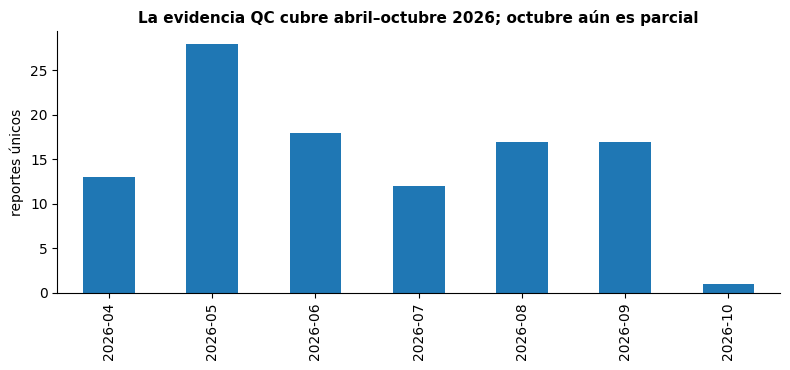

,reportes,%
Level Flag,,
1,7,6.6
2,66,62.3
3,33,31.1


In [5]:
# Cobertura QC por mes
mes = qc_reports['inspection_date'].dt.to_period('M').astype(str).value_counts().sort_index()
print(f"QC: {len(qc_reports)} reportes únicos · {qc_reports['lot_id'].nunique()} lotes · periodo {qc_reports['inspection_date'].min().date()}–{qc_reports['inspection_date'].max().date()}")
print(f"Muestra formal H1: {len(h1_sample)} reportes")
print(f"IMP: {len(wo)} Work Orders · periodo DateReceived {wo['date_received'].min().date()}–{wo['date_received'].max().date()}")

ax = mes.plot(kind='bar')
ax.set_title('La evidencia QC cubre abril–octubre 2026; octubre aún es parcial')
ax.set_xlabel(''); ax.set_ylabel('reportes únicos')
plt.tight_layout(); plt.show()

# Distribución Level Flag tal como aparece en los archivos
level_dist = qc_reports['Level_Flag'].value_counts().sort_index().rename_axis('Level Flag').to_frame('reportes')
level_dist['%'] = (level_dist['reportes'] / len(qc_reports) * 100).round(1)
display(level_dist)


> **Conclusión CAL-1** — Hay volumen suficiente para auditoría y prueba de factibilidad: 106 reportes únicos, 62 lotes, 515 muestras/pallets y 72,637 limes inspeccionados entre abril y octubre de 2026. Para una evaluación predictiva final, la unidad independiente real sigue siendo el lote/Work Order, por lo que el split debe respetar grupos y tiempo.


### CAL-2 · Completitud


In [6]:
campos = ['pallet_id','size','sample_count','oleocellosis','scars','blanching','styler','skin_breakdown','decay','mold','yellow_color']
comp = pd.DataFrame({
    'completos': [qc_rows[c].notna().sum() for c in campos],
    'total': len(qc_rows)
}, index=campos)
comp['completitud_%'] = (comp['completos'] / comp['total'] * 100).round(1)
display(comp)

faltantes_por_archivo = {}
for c in ['oleocellosis','scars','blanching','styler','skin_breakdown','decay','mold','yellow_color']:
    archivos = sorted(qc_rows.loc[qc_rows[c].isna(), 'source_file'].unique().tolist())
    if archivos:
        faltantes_por_archivo[c] = archivos
print('Archivos donde se concentran los NA de defectos:')
for c, archivos in faltantes_por_archivo.items():
    print(f"- {c}: {archivos}")

imp_key = ['RepackOrderID','LotNumber','ORDERInitialWeight','ORDERFinalWeight','ORDERLossWeightPercentage']
print('\nIMP — faltantes en campos críticos')
display((imp_loss[imp_key].isna().mean()*100).round(1).to_frame('% faltante'))


,completos,total,completitud_%
pallet_id,515,515,100.0
size,515,515,100.0
sample_count,515,515,100.0
oleocellosis,512,515,99.4
scars,513,515,99.6
blanching,506,515,98.3
styler,499,515,96.9
skin_breakdown,499,515,96.9
decay,492,515,95.5
mold,492,515,95.5


Archivos donde se concentran los NA de defectos:
- oleocellosis: ['5833.xlsx', '5857.xlsx']
- scars: ['5833.xlsx', '5857.xlsx']
- blanching: ['5833 VF.xlsx', '5833.xlsx', '5857.xlsx']
- styler: ['5833 VF.xlsx', '5833.xlsx', '5857 VF.xlsx', '5857.xlsx']
- skin_breakdown: ['5833.xlsx', '5857 VF.xlsx', '5857.xlsx']
- decay: ['5833 VF.xlsx', '5833.xlsx', '5857 VF.xlsx', '5857.xlsx']
- mold: ['5833 VF.xlsx', '5833.xlsx', '5857 VF.xlsx', '5857.xlsx']
- yellow_color: ['5833 VF.xlsx', '5833.xlsx', '5857 VF.xlsx', '5857.xlsx']

IMP — faltantes en campos críticos


,% faltante
RepackOrderID,0.0
LotNumber,0.0
ORDERInitialWeight,0.0
ORDERFinalWeight,0.0
ORDERLossWeightPercentage,0.0


> **Conclusión CAL-2** — Los campos críticos de QC superan 95% de completitud; lote, fecha, Level Flag, pallet, size y sample_count están completos. Los faltantes de defectos se concentran en unas pocas plantillas, por lo que deben mantenerse como NA hasta confirmar con QC si un blanco equivale a cero. En IMP, los campos del target no presentan faltantes.


### CAL-3 · Consistencia


In [7]:
# 1) filename vs LotNumber interno
filename_mismatch = []
for _, r in qc_reports.iterrows():
    m = re.search(r'(\d{4})', r['source_file'])
    if m and m.group(1) != str(r['lot_id']):
        filename_mismatch.append((r['source_file'], m.group(1), r['lot_id']))

# 2) claves lote+pallet repetidas
key_counts = qc_rows.groupby(['lot_id','pallet_id']).size()
repeated_keys = key_counts[key_counts > 1]

# 3) QC antes de DateReceived de IMP
min_received = imp_loss.groupby('lot_str')['DateReceived'].min()
qcr = qc_reports.copy()
qcr['DateReceived_IMP'] = qcr['lot_id'].map(min_received)
qcr['delta_days'] = (qcr['inspection_date'] - qcr['DateReceived_IMP'].dt.normalize()).dt.days
qc_before_received = qcr[qcr['delta_days'] < 0][['source_file','lot_id','inspection_date','DateReceived_IMP','delta_days']]

# 4) multi-lote y outliers target
multi_wo = int((wo['n_lots'] > 1).sum())
negative_loss = wo[wo['loss_calc'] < 0].sort_values('loss_calc')

consistencia = pd.DataFrame({
    'hallazgo': ['Duplicado exacto de archivo','Filename ≠ LotNumber interno','Claves lot+pallet repetidas','QC antes de DateReceived IMP','WO con >1 lote','WO con loss% negativo'],
    'n': [len(duplicados_exactos), len(filename_mismatch), len(repeated_keys), len(qc_before_received), multi_wo, len(negative_loss)]
})
display(consistencia)
print('Filename mismatches:', filename_mismatch)
print('Claves repetidas:', repeated_keys.to_dict())
display(qc_before_received)
print(f"Fórmula loss% validada en {(np.abs(wo['loss_calc']-wo['loss_pct']) < 1e-4).sum()}/{len(wo)} Work Orders")


,hallazgo,n
0,Duplicado exacto de archivo,1
1,Filename ≠ LotNumber interno,3
2,Claves lot+pallet repetidas,2
3,QC antes de DateReceived IMP,3
4,WO con >1 lote,343
5,WO con loss% negativo,15


Filename mismatches: [('2586.xlsx', '2586', '5280'), ('2586VF.xlsx', '2586', '5286'), ('5542.xlsx', '5542', '5502')]
Claves repetidas: {('5713', '2853'): 2, ('5743', '2866'): 2}


,source_file,lot_id,inspection_date,DateReceived_IMP,delta_days
45,5500.xlsx,5500,2026-06-12,2026-06-15 10:54:20.153,-3.0
70,5705VF.xlsx,5705,2026-07-29,2026-08-03 11:35:00.190,-5.0
93,5837VF.xlsx,5837,2026-09-17,2026-09-19 12:59:09.857,-2.0


Fórmula loss% validada en 557/557 Work Orders


> **Conclusión CAL-3** — Se detectan problemas tratables de consistencia: 1 duplicado exacto, 3 filenames que no coinciden con el LotNumber interno, 2 claves lote+pallet repetidas y 3 fechas QC anteriores a DateReceived IMP. Además, 343/557 Work Orders combinan más de un lote y 15 tienen loss% negativo; ambos puntos deben resolverse antes de modelar.


### CAL-4 · Disponibilidad en el momento de la decisión

**Momento de decisión:** después de inspeccionar la primera caja/muestra y antes de cerrar QC. Solo una variable existente hasta ese instante puede ser predictor.


In [8]:
cal4 = pd.DataFrame([
[1,'lot_id','ACC-1','En el reporte QC inicial','Sí','No','Excluir','Clave de join/grupo; no predictor.'],
[2,'pallet_id','ACC-1','En el reporte QC inicial','Sí','No','Excluir','Clave de trazabilidad; no predictor.'],
[3,'inspection_date','ACC-1','Al realizar QC','Sí','No','Transformar','Split temporal/estacionalidad.'],
[4,'label_brand','ACC-1','Antes/durante QC','Sí','No','Usar','Categoría comercial.'],
[5,'country_origin','ACC-1','Antes de QC','Sí','No','Usar','Disponible en recepción/QC.'],
[6,'size','ACC-1','Antes/durante QC','Sí','No','Usar','También permite mapear InitialProduct de IMP.'],
[7,'avg_count_per_box','ACC-1','Tras conteo de muestra inicial','Sí','No','Usar','Disponible antes de ampliar revisión.'],
[8,'sample_count','ACC-1','Al terminar conteo inicial','Sí','No','Usar','Denominador de defectos.'],
[9,'pulp_temp','ACC-1','Durante QC inicial','Sí','No','Usar','Disponible antes de cerrar QC.'],
[10,'plu_pct','ACC-1','Durante QC inicial','Sí','No','Usar','Se evaluará utilidad.'],
[11,'open_rating','ACC-1','Al evaluar primera muestra','Sí','Dudoso','Excluir','Juicio humano resumen; baseline, no feature principal.'],
[12,'color_rating','ACC-1','Al evaluar primera muestra','Sí','Dudoso','Excluir','Puede duplicar señal visual.'],
[13,'oleocellosis_pct','ACC-1','Al cerrar conteo inicial','Sí','No','Usar','Defecto disponible antes de decidir.'],
[14,'skin_breakdown_pct','ACC-1','Al cerrar conteo inicial','Sí','No','Usar','Defecto disponible antes de decidir.'],
[15,'styler_pct','ACC-1','Al cerrar conteo inicial','Sí','No','Usar','Defecto disponible antes de decidir.'],
[16,'scars_pct','ACC-1','Al cerrar conteo inicial','Sí','No','Usar','Defecto disponible antes de decidir.'],
[17,'blanching_pct','ACC-1','Al cerrar conteo inicial','Sí','No','Usar','Defecto disponible antes de decidir.'],
[18,'decay_pct','ACC-1','Al cerrar conteo inicial','Sí','No','Usar','Defecto disponible antes de decidir.'],
[19,'mold_pct','ACC-1','Al cerrar conteo inicial','Sí','No','Usar','Defecto disponible antes de decidir.'],
[20,'Level_Flag_inicial','ACC-1','Al concluir QC; orden exacto por confirmar','Dudoso','Dudoso','Excluir','Hasta confirmar timestamp vs decisión.'],
[21,'qty_received_weight','ACC-2','En recepción, antes de QC','Sí','No','Usar','Auditar 3 inconsistencias de fecha.'],
[22,'image_pixels','ACC-7','Al capturar imagen durante QC','Sí','No','Usar','Entrada del modelo CV.'],
[23,'manual_label_oleocellosis','ACC-7/QC','Después de etiquetar imágenes','No','Sí','Target','Etiqueta CV; nunca feature.'],
[24,'RepackTypeDescription','ACC-2','Al crear/ejecutar WO, normalmente después de QC','No','Dudoso','Excluir','Confusor post-decisión.'],
[25,'RepackOrderID','ACC-2','Después de QC','No','No','Excluir','ID de outcome/join.'],
[26,'ORDERInitialWeight','ACC-2','Al ingresar a producción','No','Sí','Excluir','Componente directo del target.'],
[27,'ORDERFinalWeight','ACC-2','Al finalizar producción','No','Sí','Excluir','Componente directo del target.'],
[28,'ORDERLossWeightPercentage','ACC-2','Después de producción','No','Sí','Target','Target predictivo continuo.'],
[29,'ORDERCasesLostWeight','ACC-2','Después de producción','No','Sí','Excluir','Derivado del outcome; fuga directa.'],
], columns=['#','variable','fuente','cuándo se conoce','disponible al decidir (CAL-4)','sospecha de fuga (CAL-5)','decisión','justificación'])
display(cal4)
print(cal4['disponible al decidir (CAL-4)'].value_counts())


,#,variable,fuente,cuándo se conoce,disponible al decidir (CAL-4),sospecha de fuga (CAL-5),decisión,justificación
0,1,lot_id,ACC-1,En el reporte QC inicial,Sí,No,Excluir,Clave de join/grupo; no predictor.
1,2,pallet_id,ACC-1,En el reporte QC inicial,Sí,No,Excluir,Clave de trazabilidad; no predictor.
2,3,inspection_date,ACC-1,Al realizar QC,Sí,No,Transformar,Split temporal/estacionalidad.
3,4,label_brand,ACC-1,Antes/durante QC,Sí,No,Usar,Categoría comercial.
4,5,country_origin,ACC-1,Antes de QC,Sí,No,Usar,Disponible en recepción/QC.
5,6,size,ACC-1,Antes/durante QC,Sí,No,Usar,También permite mapear InitialProduct de IMP.
6,7,avg_count_per_box,ACC-1,Tras conteo de muestra inicial,Sí,No,Usar,Disponible antes de ampliar revisión.
7,8,sample_count,ACC-1,Al terminar conteo inicial,Sí,No,Usar,Denominador de defectos.
8,9,pulp_temp,ACC-1,Durante QC inicial,Sí,No,Usar,Disponible antes de cerrar QC.
9,10,plu_pct,ACC-1,Durante QC inicial,Sí,No,Usar,Se evaluará utilidad.


disponible al decidir (CAL-4)
Sí        21
No         7
Dudoso     1
Name: count, dtype: int64


> **Conclusión CAL-4** — Se auditaron 29 variables: 21 están disponibles al momento de decidir, 1 queda dudosa por timestamp (Level Flag) y 7 aparecen después o son target/label. Los IDs pueden existir antes de la decisión, pero se excluyen como features.


### CAL-5 · Fuga del target


,variable,fuente,decisión,justificación
22,manual_label_oleocellosis,ACC-7/QC,Target,Etiqueta CV; nunca feature.
25,ORDERInitialWeight,ACC-8,Excluir,Componente directo del target.
26,ORDERFinalWeight,ACC-8,Excluir,Componente directo del target.
27,ORDERLossWeightPercentage,ACC-8,Target,Target predictivo continuo.
28,ORDERCasesLostWeight,ACC-8,Excluir,Derivado del outcome; fuga directa.


,count,mean,median,min,max
repack_type,,,,,
CONVERSION TYPE,397,24.738435,25.000000,-45.20000,85.576923
QUICK CHECK,142,10.991793,5.456349,-4.83871,88.679245
RE-STICKER,12,1.190476,0.000000,0.00000,14.285714
BOX 2 BOX REPACK,6,11.022710,7.309106,0.00000,31.666667


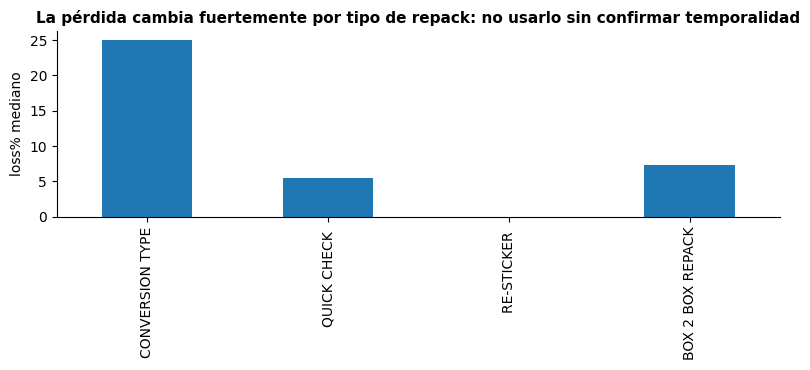

In [9]:
leaks = cal4[cal4['sospecha de fuga (CAL-5)'] == 'Sí'][['variable','fuente','decisión','justificación']]
display(leaks)

# RepackType no es target, pero muestra fuerte asociación post-decisión.
repack_stats = wo.groupby('repack_type')['loss_calc'].agg(['count','mean','median','min','max']).sort_values('count', ascending=False)
display(repack_stats)
ax = repack_stats['median'].plot(kind='bar')
ax.set_title('La pérdida cambia fuertemente por tipo de repack: no usarlo sin confirmar temporalidad')
ax.set_ylabel('loss% mediano'); ax.set_xlabel('')
plt.tight_layout(); plt.show()


> **Conclusión CAL-5** — Hay 5 variables con fuga directa o que son label: `manual_label_oleocellosis`, `ORDERInitialWeight`, `ORDERFinalWeight`, `ORDERLossWeightPercentage` y `ORDERCasesLostWeight`. `RepackTypeDescription` además es un confusor post-decisión y se excluye hasta confirmar cuándo se conoce.


### CAL-6 · Representatividad


Lotes QC con outcome IMP: 61/62 = 98.4%
WO IMP asociados a lotes QC: 549/557 = 98.6%
Loss% mediano total IMP: 19.05%
Loss% mediano en WO vinculados a QC: 19.23%


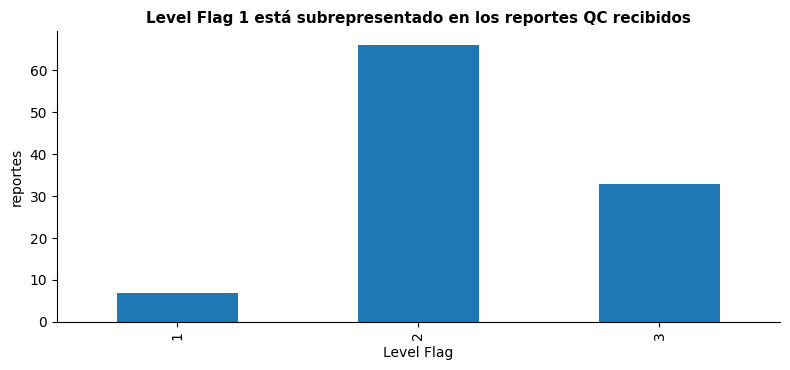

In [10]:
qc_lots = set(qc_reports['lot_id'].astype(str))
imp_lots = set(imp_loss['lot_str'].astype(str))
lot_match = len(qc_lots & imp_lots)

wo_lots = imp_loss.groupby('RepackOrderID')['lot_str'].agg(set)
linked_wo_ids = [woid for woid, lots in wo_lots.items() if len(lots & qc_lots) > 0]
linked_wo = wo[wo['RepackOrderID'].isin(linked_wo_ids)]

print(f"Lotes QC con outcome IMP: {lot_match}/{len(qc_lots)} = {pct(lot_match/len(qc_lots))}")
print(f"WO IMP asociados a lotes QC: {len(linked_wo_ids)}/{len(wo)} = {pct(len(linked_wo_ids)/len(wo))}")
print(f"Loss% mediano total IMP: {wo['loss_calc'].median():.2f}%")
print(f"Loss% mediano en WO vinculados a QC: {linked_wo['loss_calc'].median():.2f}%")

level_dist = qc_reports['Level_Flag'].value_counts().sort_index()
ax = level_dist.plot(kind='bar')
ax.set_title('Level Flag 1 está subrepresentado en los reportes QC recibidos')
ax.set_xlabel('Level Flag'); ax.set_ylabel('reportes')
plt.tight_layout(); plt.show()


> **Conclusión CAL-6** — Los reportes no fueron sorteados por el equipo y varios pertenecen al mismo lote, por lo que no deben tratarse como observaciones independientes. Sin embargo, la cobertura sobre IMP es alta y la mediana de loss% de los WO vinculados es muy similar a la del total. El split de train/test debe hacerse por lote, no por reporte o Work Order individual.


### CAL-7 · Target


Target predictivo: loss% = (ORDERInitialWeight - ORDERFinalWeight) / ORDERInitialWeight × 100
Fórmula validada en 557/557 Work Orders


Media=20.58% · mediana=19.05% · rango=-45.20% a 88.68%
Negativos=15 · cero=24 · >50%=23
WO multi-lote=343/557 = 61.6% · máximo 6 lotes/WO


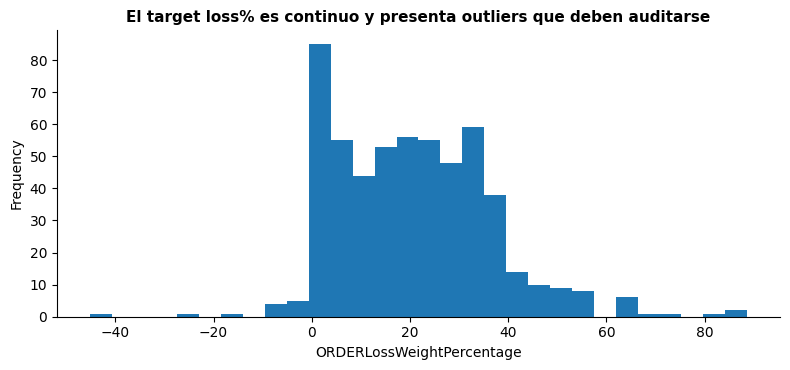

In [11]:
formula_ok = (np.abs(wo['loss_calc'] - wo['loss_pct']) < 1e-4).sum()
print(f"Target predictivo: loss% = (ORDERInitialWeight - ORDERFinalWeight) / ORDERInitialWeight × 100")
print(f"Fórmula validada en {formula_ok}/{len(wo)} Work Orders")
print(f"Media={wo['loss_calc'].mean():.2f}% · mediana={wo['loss_calc'].median():.2f}% · rango={wo['loss_calc'].min():.2f}% a {wo['loss_calc'].max():.2f}%")
print(f"Negativos={(wo['loss_calc']<0).sum()} · cero={(wo['loss_calc']==0).sum()} · >50%={(wo['loss_calc']>50).sum()}")
print(f"WO multi-lote={(wo['n_lots']>1).sum()}/{len(wo)} = {pct((wo['n_lots']>1).mean())} · máximo {wo['n_lots'].max()} lotes/WO")

ax = wo['loss_calc'].plot(kind='hist', bins=30)
ax.set_title('El target loss% es continuo y presenta outliers que deben auditarse')
ax.set_xlabel('ORDERLossWeightPercentage')
plt.tight_layout(); plt.show()


> **Conclusión CAL-7** — El target predictivo es continuo y queda validado por fórmula en 557/557 Work Orders. Como 343/557 WO contienen más de un lote, el target debe modelarse a nivel Work Order salvo que IMP permita una desagregación real por lote. Los 15 valores negativos y los extremos >50% deben revisarse con Operaciones antes de entrenar.


## H · Hipótesis frente a evidencia

Se conserva el **preregistro original**. Los resultados de este bloque muestran qué podía contrastarse en el checkpoint E4.

Después de E4 sí se desarrollaron y evaluaron componentes de Vision y experimentos sobre pérdida posterior. Esa evidencia posterior se documenta en las secciones `FINAL`, pero **no cambia retroactivamente el veredicto de las hipótesis preregistradas**.

Si una hipótesis original no pudo contrastarse con su criterio exacto, permanece como `No testeable` bajo ese criterio, aunque posteriormente el proyecto haya avanzado técnicamente.


In [12]:
print('Señal preliminar variables–target:')
print('- No se estima todavía una correlación lote→loss% como si cada WO fuera independiente, porque 61.6% de los WO combinan varios lotes.')
print('- Primero se debe definir la unidad analítica y agregar correctamente las features QC de los lotes dentro de cada Work Order.')


Señal preliminar variables–target:
- No se estima todavía una correlación lote→loss% como si cada WO fuera independiente, porque 61.6% de los WO combinan varios lotes.
- Primero se debe definir la unidad analítica y agregar correctamente las features QC de los lotes dentro de cada Work Order.


### H1 · Acceso

| Pre-registro original | |
|---|---|
| Hipótesis | A más tardar el 10/10/2026, QC/KIMA podrá entregar un extracto de al menos 100 casos de 2025 con ID de lote/pallet, datos de QC inicial, Level Flag y campo de resultado posterior cuando exista. |
| Ajuste documentado | Ventana 2025 → **2026**; se conserva **n=100** como muestra formal. |
| Fecha del pre-registro | 03/10/2026 |


In [13]:
h1_ok = len(h1_sample) >= 100 and h1_sample['inspection_date'].dt.year.eq(2026).all()
print(f"Muestra formal: {len(h1_sample)} reportes únicos")
print(f"Periodo: {h1_sample['inspection_date'].min().date()}–{h1_sample['inspection_date'].max().date()}")
print('Campos básicos completos en los 100 reportes:')
print(h1_sample[['lot_id','inspection_date','Level_Flag']].notna().mean().mul(100).round(1).to_string())
print('\nVeredicto:', 'Sostenida tras ajuste documentado' if h1_ok else 'No sostenida')


Muestra formal: 100 reportes únicos
Periodo: 2026-04-13–2026-09-29
Campos básicos completos en los 100 reportes:
lot_id             100.0
inspection_date    100.0
Level_Flag         100.0

Veredicto: Sostenida tras ajuste documentado


> **Veredicto H1: Sostenida tras ajuste documentado.** Se confirmó el acceso y se formalizó una muestra de 100 reportes únicos de 2026. El cambio de ventana temporal está registrado en la hoja Cambios.


### H2 · Linkage QC ↔ outcome posterior

| Pre-registro original | |
|---|---|
| Hipótesis | Al menos 80% de los casos con resultado posterior podrá enlazarse con su QC inicial mediante un ID común de lote/pallet. |
| Qué la refutaría | Match <80%, IDs sin trazabilidad o falta de información temporal mínima para diferenciar repack inmediato/posterior. |
| Fecha del pre-registro | 03/10/2026 |


In [14]:
qc_lots = set(qc_reports['lot_id'].astype(str))
imp_lots = set(imp_loss['lot_str'].astype(str))
lot_match_n = len(qc_lots & imp_lots)
lot_match_rate = lot_match_n / len(qc_lots)
ci = wilson_ci(lot_match_n, len(qc_lots))

report_match_n = qc_reports['lot_id'].astype(str).isin(imp_lots).sum()

# Match más fino lot+size
qc_pairs = set(zip(qc_rows['lot_id'].astype(str), qc_rows['size'].map(_norm_size)))
qc_key_lots = set(qc_rows.loc[qc_rows['size'].astype(str).str.contains('10x1', case=False, na=False), 'lot_id'])
imp_rel = imp_loss[imp_loss['lot_str'].isin(qc_lots)].copy()
imp_rel['size_norm'] = imp_rel['InitialProduct'].astype(str).str.extract(r'(\d{2,3})', expand=False)
base_match = [(l, s) in qc_pairs for l, s in zip(imp_rel['lot_str'], imp_rel['size_norm'])]
key_like = imp_rel['InitialProduct'].astype(str).str.contains('KLB|1LB', case=False, regex=True) & imp_rel['lot_str'].isin(qc_key_lots)
imp_rel['match_lot_size'] = np.array(base_match) | key_like.to_numpy()
full_wo_match = imp_rel.groupby('RepackOrderID')['match_lot_size'].all()

print(f"Lotes QC con IMP: {lot_match_n}/{len(qc_lots)} = {pct(lot_match_rate)} · IC95% Wilson [{pct(ci[0])}, {pct(ci[1])}]")
print(f"Reportes QC con IMP: {report_match_n}/{len(qc_reports)} = {pct(report_match_n/len(qc_reports))}")
print(f"Filas IMP lot+size con match: {imp_rel['match_lot_size'].sum()}/{len(imp_rel)} = {pct(imp_rel['match_lot_size'].mean())}")
print(f"WO relevantes completamente mapeados: {full_wo_match.sum()}/{len(full_wo_match)} = {pct(full_wo_match.mean())}")
print('Timestamp de repack/producción para medir QC→repack: NO está en el extracto recibido.')


Lotes QC con IMP: 61/62 = 98.4% · IC95% Wilson [91.4%, 99.7%]
Reportes QC con IMP: 105/106 = 99.1%
Filas IMP lot+size con match: 742/759 = 97.8%
WO relevantes completamente mapeados: 532/549 = 96.9%
Timestamp de repack/producción para medir QC→repack: NO está en el extracto recibido.


> **Veredicto H2: No testeable completa, pero el componente de enlace está sostenido.** El match por lote es 98%+, muy por encima del 80%. Falta el timestamp posterior exigido por la formulación original y debe resolverse la granularidad multi-lote de los Work Orders.


### H3 · Dataset visual

| Pre-registro original | |
|---|---|
| Hipótesis | Generar 200 fotografías bajo protocolo fijo, ≥90% utilizables y con ambas clases representadas. |
| Cambio documentado | Defecto objetivo operativo: **Styler → oleocelosis** por disponibilidad de positivos. |
| Fecha del pre-registro | 03/10/2026 |

Las fotografías preliminares se utilizaron para evaluar el protocolo de captura. Debido a que no existía trazabilidad suficiente para identificar si un mismo fruto físico reaparecía en distintas imágenes, no se utilizaron para estimar el desempeño final. El diseño posterior separó físicamente los grupos de desarrollo y test y contempló etiquetado independiente por dos evaluadores.

La evidencia posterior muestra que Vision fue integrada técnicamente al MVP mediante inferencia con pesos existentes, resultados estructurados por fotografía y agregación de múltiples imágenes por caja. Esta evidencia de integración se documenta en `H3-FINAL` y se mantiene separada del criterio literal del preregistro.


#### H3.1 · Evidencia histórica para elegir el defecto

Este análisis **no prueba H3**. Solo justifica por qué el defecto objetivo cambió de Styler a oleocelosis usando los reportes QC históricos.


,defecto,positivos,muestras_validas,% con defecto
0,Oleocelosis,465,512,90.820312
1,Styler,126,499,25.250501


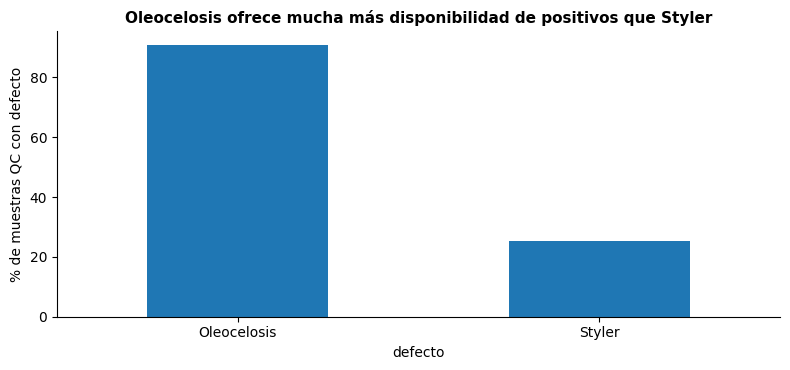

In [15]:
oleo_valid = qc_rows['oleocellosis'].notna()
oleo_pos = (qc_rows.loc[oleo_valid, 'oleocellosis'] > 0).sum()
styler_valid = qc_rows['styler'].notna()
styler_pos = (qc_rows.loc[styler_valid, 'styler'] > 0).sum()

defect_avail = pd.DataFrame({
    'defecto': ['Oleocelosis','Styler'],
    'positivos': [oleo_pos, styler_pos],
    'muestras_validas': [oleo_valid.sum(), styler_valid.sum()]
})
defect_avail['% con defecto'] = defect_avail['positivos'] / defect_avail['muestras_validas'] * 100
display(defect_avail)

ax = defect_avail.set_index('defecto')['% con defecto'].plot(kind='bar', rot=0)
ax.set_title('Evidencia histórica para seleccionar el defecto objetivo')
ax.set_ylabel('% de muestras QC con al menos un caso')
plt.tight_layout(); plt.show()


## DS · Datasheet final del sistema de datos

| ID | Sección | Respuesta |
|---|---|---|
| DS-1 | Motivación | SmartFruit combina datos históricos QC y reglas de negocio con un manifest de recepción, resultados de Vision y la captura generada por el MVP. El objetivo operativo es apoyar al inspector para registrar la muestra, automatizar conteo y oleocelosis, completar otros defectos y sugerir `STANDARD / EXPAND / ESCALATE` sin reemplazar la decisión humana. IMP/repack queda como fuente experimental. |
| DS-2 | Composición | Histórico QC: 106 reportes únicos, 62 lotes, 515 filas pallet/muestra y 72,637 frutos. IMP: 557 Work Orders. MVP: manifest por lote/paleta; un JSON Vision por fotografía; múltiples imágenes agregadas por `sample_box_id`; una fila QC por paleta con historial de cajas adicionales. |
| DS-3 | Recolección | QC/IMP corresponden a operación 2026. Vision fue desarrollado mediante experimentación separada y la app final reutiliza pesos existentes para inferencia local. En el MVP el inspector confirma la cobertura física de cada caja, completa defectos manuales y confirma Level Flag/decisión final. |
| DS-4 | Preprocesamiento | Histórico: deduplicación, normalización y auditoría de faltantes/outliers. Integración: `image_id` único, asociación externa imagen↔muestra, suma de counts por caja, `oleocellosis_pct` desde cantidades acumuladas y comparación `actual_count` vs `expected_count_per_box`. |
| DS-5 | Usos | Apropiado para soporte de QC de recepción, trazabilidad, conteo/oleocelosis asistidos, reglas y QC Report. No usar la sugerencia como aprobación/rechazo autónomo, ni `predicted_loss_pct` como Hidden Quality Risk, ni `count_difference` como confirmación automática de faltante del proveedor. |
| DS-6 | Limitaciones | Los históricos no son muestra aleatoria; Level 1 está subrepresentado. La validación técnica del software no sustituye validación operativa de Vision. Aún no existe `decision_log.csv` independiente, `triggered_rules` estructurado completo ni outcomes reales suficientes para medir Precision Expand. El estimador de pérdida permanece experimental y OFF por defecto. |


## ACC-9 · Reception Manifest del MVP

El manifest es una fuente **operativa de integración**, no una fuente de entrenamiento.

Campos mínimos utilizados por la aplicación:

- `lot_id`
- `pallet_id`
- `scan_code` cuando existe
- `label_brand`
- `country_origin`
- `size_declared`
- `expected_count_per_box`

`expected_count_per_box` representa la declaración de unidades **por caja**. No se usa como si fuera el total de una paleta y no sustituye el conteo observado por Vision.

La aplicación conserva los datos ausentes como pendientes; no inventa valores de otros documentos.


## ACC-10 · Vision outputs de la integración

Vision produce un resultado por fotografía/entrada. El contrato incluye:

- `image_id`
- `total_fruits`
- `oleocellosis_count`
- `oleocellosis_pct`
- `mean_confidence`
- `fruit_predictions`

Los identificadores comerciales (`lot_id`, `pallet_id`, `sample_id`, `sample_box_id`) se asocian externamente en la integración.

### Agregación por caja

```text
actual_count = suma de total_fruits de imágenes únicas
oleocellosis_count = suma de oleocellosis_count
oleocellosis_pct = 100 × oleocellosis_count / actual_count
```

**No se promedian porcentajes de fotografías.**

Un `image_id` duplicado no debe aumentar conteos. La aplicación no puede reconocer de forma general que el mismo fruto fue fotografiado desde ángulos distintos; el protocolo físico debe evitar ese solapamiento.


## ACC-11 · Captura integrada / QC Report

La jerarquía final del MVP es:

```text
Manifiesto
  → lote
    → paleta
      → caja inspeccionada
        → múltiples fotografías/JSON
```

La integración mantiene:

- `sample_box_id` por caja;
- detalle de las cajas inspeccionadas;
- agregados Vision;
- los 16 campos de defectos del QC, con oleocelosis proveniente de Vision y los demás ingresados por QC;
- Business Severity;
- sugerencia `STANDARD / EXPAND / ESCALATE`;
- Level Flag y decisión final del inspector;
- historial cuando se amplía a otra caja;
- QC Report y JSON de salida.

Una fila QC representa una paleta/muestra. Si se agrega otra caja, los campos de la fila pasan a representar el acumulado de las cajas inspeccionadas y el historial conserva el detalle por caja.


## CAL-3F · Consistencia del flujo integrado

Además de los hallazgos históricos de `CAL-3`, el cierre del MVP exige:

1. `image_id` único dentro de la captura y asociación consistente con lote/paleta/muestra.
2. No sumar dos veces el mismo JSON.
3. Agregar conteos antes de calcular porcentajes.
4. Comparar cada caja contra su propio `expected_count_per_box`.
5. No comparar el total acumulado de dos cajas contra el expected de una sola caja.
6. No convertir `count_difference` en una regla de severidad sin un umbral aprobado por QC.
7. Mantener un protocolo físico que evite fotografiar el mismo fruto en varias tomas.

La diferencia de conteo es **descriptiva**. Una diferencia no demuestra por sí sola que el proveedor entregó unidades de más o de menos.


## CAL-4F · Disponibilidad en la decisión final

El momento operativo actual es:

> Después de completar y agregar la primera caja/muestra, registrar los defectos QC disponibles y antes de que el inspector confirme su decisión final.

Variables disponibles en ese instante:

**Reception / Manifest**
- `lot_id`, `pallet_id`
- `label_brand`, `country_origin`
- `size_declared`
- `expected_count_per_box`

**Vision**
- `actual_count`
- `oleocellosis_count`
- `oleocellosis_pct`

**QC manual**
- defectos no automatizados
- mediciones/ratings disponibles durante la inspección

**Derivadas por Rules Engine**
- severidades por defecto
- `business_max_level`
- `final_recommendation`

No se usa como input de la sugerencia:

- `inspector_final_decision`
- una recomendación independiente de QC usada para validar
- outcome posterior de una segunda inspección
- variables de producción/repack posteriores


## CAL-5F · Fuga y variables posteriores

La separación final es:

- `final_recommendation` = salida calculada del Rules Engine.
- `qc_header.Level_Flag` = registro/juicio final del inspector; no se infiere automáticamente desde Business Severity.
- `inspector_final_decision` = decisión humana posterior a la sugerencia.
- `qc_expert_recommendation` = referencia futura para concordancia.
- `additional_quality_issue_found_after_expand` = outcome futuro para evaluar utilidad real de `EXPAND`.

Los tres últimos campos **no pueden alimentar la recomendación que luego se pretende evaluar contra ellos**.

Para el experimento de pérdida posterior continúan excluidos como fuga directa `ORDERInitialWeight`, `ORDERFinalWeight`, `ORDERLossWeightPercentage` y derivados del mismo outcome.


## CAL-6F · Representatividad y validación

Se deben mantener separadas tres preguntas:

1. **¿El software implementa correctamente las reglas?**  
   Casos controlados con expected vs actual recommendation.

2. **¿La sugerencia coincide con el criterio de QC?**  
   Revisión de casos por experto, idealmente sin mostrarle primero la sugerencia.

3. **¿EXPAND realmente descubre información adicional útil?**  
   Requiere segunda inspección real y registrar si apareció calidad adicionalmente problemática.

Las pruebas unitarias/integración y una demo controlada responden la primera pregunta.  
No deben presentarse como evidencia suficiente de las preguntas 2 o 3.


## CAL-7F · Targets, salidas y rol del componente experimental

### Vision

Target técnico:

```text
oleocellosis ∈ {con_oleocelosis, sin_oleocelosis}
```

Unidad: fruto/crop.

### Rules Engine / Decision Layer

No existe un target ML.

```text
Vision + defectos QC + reglas → STANDARD / EXPAND / ESCALATE
```

La sugerencia es rule-based y permanece sujeta a revisión humana.

### Post-QC Loss Estimator

El notebook experimental estudia pérdida posterior a partir de señales del primer QC. Su salida prevista en integración es:

```text
predicted_loss_pct
```

No representa directamente probabilidad de Hidden Quality Risk ni recomendación de inspección.

Estado operativo:

```text
USE_PREDICTIVE = False
recomendación = reglas de negocio + revisión del inspector
```

### Outcome de negocio futuro

Cuando exista trazabilidad real de la ampliación, el outcome relevante será si revisar otra caja reveló calidad adicionalmente problemática. Ese dato permitirá medir `Precision Expand` y `Recall Expand` y eventualmente estudiar un modelo de riesgo más alineado con la decisión.


## H2-FINAL · Resultado posterior al checkpoint

El linkage histórico QC↔IMP fue alto y permitió explorar la pérdida posterior.

El criterio original de H2 incluía además la temporalidad QC→repack para distinguir resultados inmediatos de resultados posteriores. Esa dimensión no quedó demostrada con la evidencia disponible.

El análisis posterior mostró que `loss%` puede utilizarse como outcome histórico exploratorio, pero no es equivalente a la necesidad de ampliar la inspección ni a Hidden Quality Risk.

**Resultado:** IMP/loss% se conserva como línea experimental y el MVP operativo no depende del Post-QC Loss Estimator.


## H3-FINAL · Evidencia posterior sobre Vision

Después del checkpoint, Vision pasó a formar parte de la integración técnica del MVP.

La aplicación:
- utiliza un clasificador ResNet18 con pesos existentes;
- puede utilizar YOLO para localizar frutos en fotografías completas;
- procesa entradas nuevas/locales;
- genera resultados estructurados por fotografía;
- agrega conteo y oleocelosis por caja;
- mantiene revisión humana de los resultados.

**Resultado:** se demostró factibilidad técnica e integración de Vision dentro del flujo SmartFruit.

El criterio original de H3 sobre una campaña de 200 fotografías, porcentaje de imágenes utilizables y representación de clases se conserva como un contraste metodológico distinto de la evidencia de integración.


## Arquitectura del MVP resultante

```text
MANIFEST
   ↓
LOTE + PALETA
   ↓
CAJA / SAMPLE_BOX
   ↓
MÚLTIPLES FOTOS
   ↓
VISION
   ├─ actual_count
   └─ oleocellosis
   ↓
QC MANUAL
   ↓
BUSINESS SEVERITY / RULES ENGINE
   ↓
STANDARD / EXPAND / ESCALATE
   ↓
LEVEL FLAG + DECISIÓN FINAL DEL INSPECTOR
   ↓
QC REPORT + JSON + EVIDENCIA
```

### Componentes y capacidades fuera de la decisión operativa actual

- Post-QC Loss Estimator: experimental, OFF por defecto.
- `count_difference`: señal descriptiva; no tiene umbral operativo nuevo aprobado.
- `4+ decay`: criterio histórico conocido, pero no se declara implementado en el motor final si no existe una regla explícita en el runtime.
- `qc_expert_recommendation`, `decision_log.csv` y outcome completo de `Precision Expand`: pendientes de piloto/validación.


In [ ]:
import platform
problemas = []
avisos = []

if MODO_DEMO:
    problemas.append('MODO_DEMO sigue en True.')
if len(qc_reports) < 100:
    problemas.append('Hay menos de 100 reportes QC únicos.')
if len(cal4) == 0:
    problemas.append('CAL-4 está vacío.')
if len(wo) == 0:
    problemas.append('No se cargó IMP / Work Orders.')

pii_tokens = ('dni','nombre_persona','correo','email','telefono','celular','direccion')
cols_all = [c.lower() for c in list(qc_rows.columns) + list(imp_loss.columns)]
pii = [c for c in cols_all if any(k in c for k in pii_tokens)]
if pii:
    problemas.append(f'Posibles columnas PII: {sorted(set(pii))}')

if VISUAL_DIR is None:
    avisos.append('ACC-7/H3 preparado, pero la nueva carpeta compartida aún no está conectada.')
elif visual_inventory.empty:
    avisos.append('ACC-7 conectado, pero no se encontraron imágenes compatibles.')

print(f"Python {platform.python_version()} · pandas {pd.__version__}")
print(f"ACC-1 QC: {len(qc_reports)} reportes únicos · {len(qc_rows)} muestras")
print(f"ACC-2 IMP: {len(wo)} Work Orders")
print("ACC-7 visual:", "pendiente de nueva captura" if VISUAL_DIR is None else str(VISUAL_DIR))

if avisos:
    print('\nAvisos:')
    for a in avisos:
        print('  -', a)

if problemas:
    print('\n⚠ Revisar antes de entregar:')
    for p in problemas:
        print('  -', p)
else:
    print('\n✓ Notebook v2 consistente. Cuando se conecte ACC-7, H3 se recalcula sin cambiar el código.')
